In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())
display(df.head())

['transaction_id', 'date', 'customer_id', 'gender', 'age', 'product_category', 'quantity', 'price_per_unit', 'total_amount']


,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [25]:
df["total_amount"] = pd.to_numeric(
    df["total_amount"], errors="coerce"
)

df["quantity"] = pd.to_numeric(
    df["quantity"], errors="coerce"
)

df = df.dropna(
    subset=["product_category", "total_amount"]
)

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (1000, 9)


In [27]:
category_sales = (
    df.groupby("product_category", as_index=False)["total_amount"]
      .sum()
      .sort_values("total_amount", ascending=False)
)

category_sales.columns = ["Product Category", "Total Sales"]
display(category_sales)

,Product Category,Total Sales
2,Electronics,156905
1,Clothing,155580
0,Beauty,143515


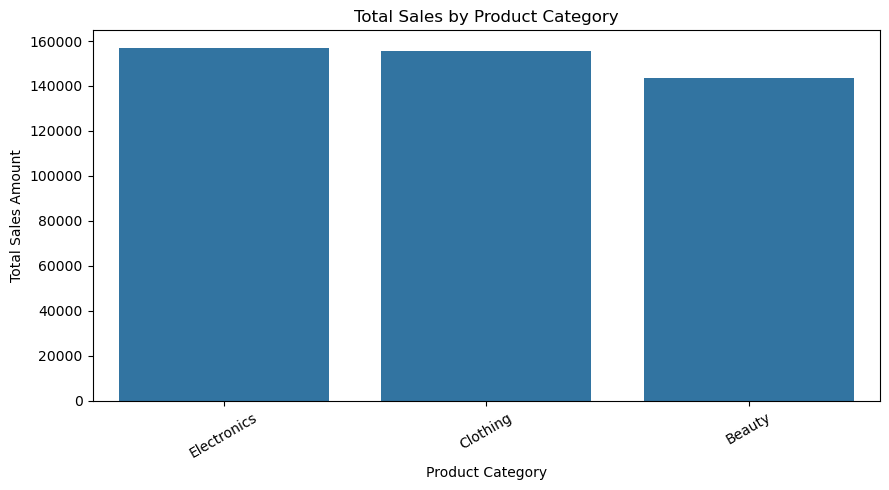

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_sales,
    x="Product Category",
    y="Total Sales"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [31]:
best_category = category_sales.iloc[0]

print("Top-performing product category:",
      best_category["Product Category"])

print("Total sales:",
      best_category["Total Sales"])

Top-performing product category: Electronics
Total sales: 156905


In [33]:
gender_category_sales = (
    df.groupby(["gender", "product_category"], as_index=False)
      ["total_amount"].sum()
)

gender_category_sales.columns = [
    "Gender", "Product Category", "Total Sales"
]

display(gender_category_sales)

,Gender,Product Category,Total Sales
0,Female,Beauty,74830
1,Female,Clothing,81275
2,Female,Electronics,76735
3,Male,Beauty,68685
4,Male,Clothing,74305
5,Male,Electronics,80170


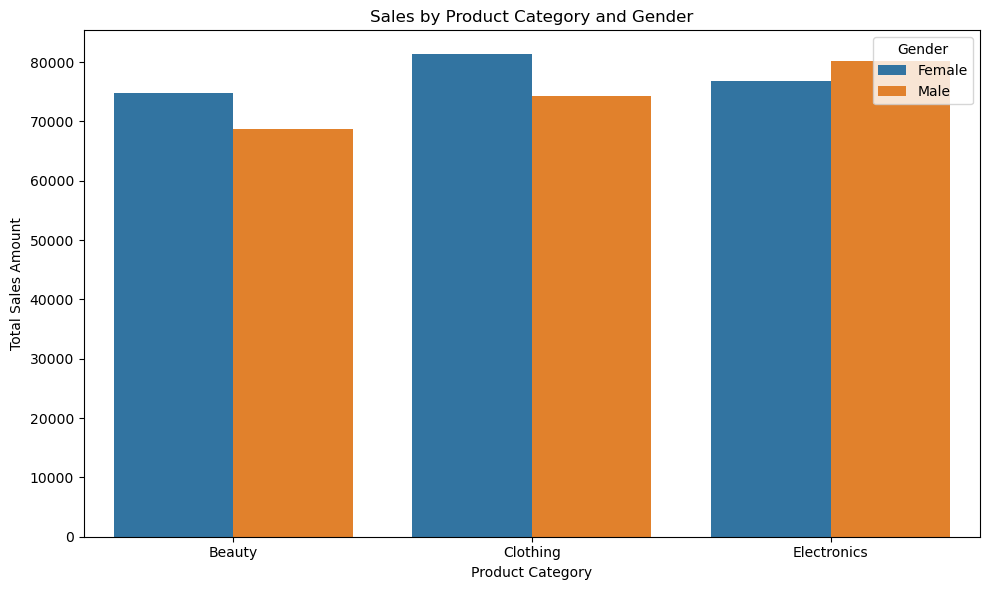

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=gender_category_sales,
    x="Product Category",
    y="Total Sales",
    hue="Gender"
)

plt.title("Sales by Product Category and Gender")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.tight_layout()
plt.show()